# Reproducing the published neural network: its seeds, its widths and what its hold-out score is worth

**Level 3: State of the art** · Needs: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 05-learned-arms/02-every-arm-and-why-each-one-refuses · Reading time: about 30 minutes

## Objectives

Kulatilake, Hudaverdi and Wu 2012 trained a small neural network on this corpus and reported it as the best of three predictors on a 12-blast hold-out. The engine reproduces the network to its published specification. This notebook asks what that published score is worth when the network's random initialisation and its hidden width are varied.

By the end you will have:

- retrained the network under 30 seeds and placed the published hold-out score among them;
- reproduced the source's width selection and compared the widths it picks with the published ones;
- read what the width does to the network held out by site, beside the null.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 training blasts and the 12-blast hold-out with the network's printed predictions | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the articles never ship | the corpus and `bf.load_holdout(protocol="2012")` inside the `blastfrag` wheel |
| The committed seed sweep and width sweep | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, fields `network_seed_sweep` and `network_width_sweep` |

## Method

The network of Kulatilake et al. 2012 (https://doi.org/10.1007/s10706-012-9496-3, section 5) is specified fully enough to reproduce:

- one network per rock-stiffness group, each trained on that group's rows only; the group comes from the published discriminant;
- seven inputs, one hidden layer with a logistic activation, one output, min-max normalisation of inputs and target (their Eq. 11);
- Levenberg-Marquardt training, eight simulations per width averaged, and a hidden width swept from 6 to 15 and chosen on the hold-out by RMSE and correlation, which gave 9 for the first group and 7 for the second.

Two things follow from the specification and the engine states them rather than correcting them: the output is clamped to the range of the training targets, so a held-out site with coarser fragments than every training site cannot be predicted at all, and the widths are the published optima, which the source chose on its own hold-out.

### Step 1: the published score and 30 seeds

The cell scores the network's printed predictions on the 12-blast hold-out (the published figure), then retrains the engine's reproduction 30 times, each time with a different seed for the weight initialisation, on the whole corpus, and scores the hold-out. It takes about half a minute.

In [2]:
# Imports, the published score of the printed network column and 30 retrainings under different seeds
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from blastfrag.learned import PublishedNeuralNetwork

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
holdout = bf.load_holdout(protocol="2012")
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
printed = [bf.Prediction(method="published", blast_id=b.blast_id, x50_m=b.meta["published"]["nn_mean_2012"]) for b in holdout]
published = bf.score(holdout, printed).r2_identity
seed_scores = []
for seed in range(30):
    network = PublishedNeuralNetwork(seed=seed).fit(train)
    seed_scores.append(bf.score(holdout, network.predict(holdout)).r2_identity)
seed_scores = np.array(sorted(seed_scores))
print(f"published (printed column) r2_identity = {published:.4f}")
print(f"reproduced, 30 seeds: min {seed_scores.min():.3f} | median {np.median(seed_scores):.3f} | max {seed_scores.max():.3f}")
print("published above every seed:", bool(published > seed_scores.max()))
want = benchmark["network_seed_sweep"]
print("equals the committed sweep:", bool(np.allclose(seed_scores, want["r2_identity"], atol=1e-9)))

published (printed column) r2_identity = 0.9096
reproduced, 30 seeds: min 0.167 | median 0.340 | max 0.636
published above every seed: True
equals the committed sweep: True


The next cell draws the 30 scores as a strip with the published value, so the position of the published figure is visible at a glance.

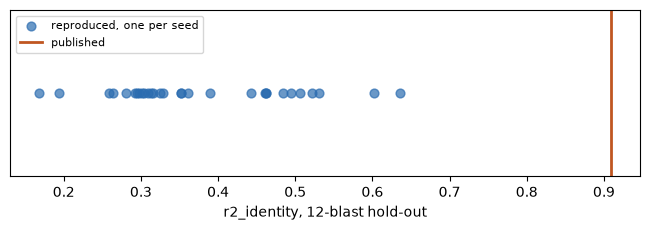

In [3]:
# The 30 reproduced scores against the published one
fig, ax = plt.subplots(figsize=(6.6, 2.4))
ax.scatter(seed_scores, np.zeros_like(seed_scores), s=40, alpha=0.7, color="#2b6cb0", label="reproduced, one per seed")
ax.axvline(published, color="#c05621", lw=2, label="published")
ax.set_yticks([])
ax.set_xlabel("r2_identity, 12-blast hold-out")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

### Step 2: does the source's width selection land on the published widths?

`sweep_hidden_width` repeats the selection: for each width from 6 to 15 it trains the network and scores the hold-out rows of each group, and picks the width with the lowest RMSE. The cell prints the width it picks per group beside the published one and the full RMSE table of each group, then compares the chosen widths with the committed sweep.

In [4]:
# Repeat the width selection of the source and compare with the published widths and the committed sweep
sweep = PublishedNeuralNetwork(n_simulations=8, seed=0).sweep_hidden_width(train, holdout)
committed = benchmark["network_width_sweep"]["published_protocol"]
for group, entry in sweep.items():
    print(f"group {group}: this notebook picks {entry['best_hidden']} | published {entry['published_optimum']} | committed sweep picks {committed[str(group)]['best_hidden']}")
    row = {r["hidden"]: r for r in entry["table"]}
    print("   RMSE (m) by width:", {w: round(r["rmse"], 3) for w, r in row.items()})
    print("   correlation by width:", {w: round(r["correlation"], 2) for w, r in row.items()})

group 1: this notebook picks 8 | published 9 | committed sweep picks 8
   RMSE (m) by width: {6: 0.085, 7: 0.072, 8: 0.037, 9: 0.102, 10: 0.053, 11: 0.045, 12: 0.072, 13: 0.109, 14: 0.059, 15: 0.09}
   correlation by width: {6: 0.91, 7: 0.94, 8: 0.97, 9: 0.8, 10: 0.95, 11: 0.96, 12: 0.94, 13: 0.92, 14: 0.95, 15: 0.88}
group 2: this notebook picks 11 | published 7 | committed sweep picks 11
   RMSE (m) by width: {6: 0.125, 7: 0.133, 8: 0.153, 9: 0.14, 10: 0.142, 11: 0.106, 12: 0.157, 13: 0.157, 14: 0.125, 15: 0.147}
   correlation by width: {6: 0.91, 7: 0.92, 8: 0.91, 9: 0.9, 10: 0.91, 11: 0.88, 12: 0.9, 13: 0.92, 14: 0.89, 15: 0.9}


### Step 3: the width held out by site

The committed width sweep also scored every width, the same in both groups, under leave-one-site-out, beside the published pair. The cell lists them with the null for reference and draws the held-out score against the width.

widths (group 1, group 2)       all 97          91 with geometry
9, 7 (published)                -0.626                    -0.604
6, 6                            -0.605                    -0.630
7, 7                            -0.653                    -0.635
8, 8                            -0.626                    -0.562
9, 9                            -0.586                    -0.604
10, 10                          -0.902                    -0.955
11, 11                          -0.568                    -0.681
12, 12                          -1.027                    -1.169
13, 13                          -0.717                    -0.747
14, 14                          -1.257                    -1.296
15, 15                          -1.486                    -1.603
null (all 97) = -0.216


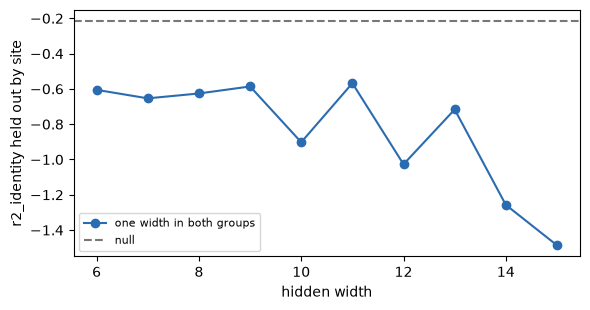

In [5]:
# Held-out score of every width, from the committed sweep, beside the published pair and the null
table = benchmark["network_width_sweep"]["leave_one_site_out"]
null = benchmark["verdict"]["null_r2_identity"]
print(f"{'widths (group 1, group 2)':<28}{'all 97':>10}{'91 with geometry':>26}")
for row in table:
    label = f"{row['hidden']['1']}, {row['hidden']['2']}" + (" (published)" if row["published"] else "")
    print(f"{label:<28}{row['supports']['all']['r2_identity']:>10.3f}{row['supports']['geometry']['r2_identity']:>26.3f}")
print("null (all 97) =", round(null, 3))

widths = [row["hidden"]["1"] for row in table if not row["published"]]
held = [row["supports"]["all"]["r2_identity"] for row in table if not row["published"]]
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(widths, held, "o-", color="#2b6cb0", label="one width in both groups")
ax.axhline(null, color="#777", ls="--", label="null")
ax.set_xlabel("hidden width")
ax.set_ylabel("r2_identity held out by site")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## State of the art

- **Kulatilake, Hudaverdi and Wu 2012** (https://doi.org/10.1007/s10706-012-9496-3) is the reference for the network: the specification in the Method section and a hold-out of 12 blasts on which it reaches the best of the three printed predictors.
- The source's own tables show the width choice is unstable: the correlation of one group swings between 0.11 and 0.81 across adjacent widths, according to the engine's documentation of the network.
- The published network is a single trained instance. The state of the art reports one score, with no spread over the initialisation and no site held out.

## Results

**The published score is above every reproduced seed.** Under 30 initialisations the reproduction scores between about 0.17 and 0.64 on the hold-out, with a median near 0.34, while the printed predictions score 0.91. The reproduction follows the published specification; what it cannot reproduce is that single printed result. The notebook's 30 scores equal the committed sweep.

**The width selection does not land on the published widths.** Repeated with the source's procedure, the selection picks a different width for each group, and the RMSE table moves a lot between neighbouring widths: the choice rests on eight simulations and twelve hold-out blasts and is not stable.

**Held out by site no width helps.** Every width from 6 to 15, and the published pair, score below zero, and the best widths do no better than the null. The widest networks do worst, which is what overfitting ten campaigns predicts. The width the source optimised on its own hold-out transfers to no better result at a new mine.

**What this does not show.** It does not show the source's network was misreported: a single initialisation can be better than the median of many, and the source may have chosen among several. It shows the published number is not a property of the specification, and that the product therefore cannot present it as the network's expected performance.

## Summary

- The network is reproduced to its specification; its published hold-out score lies above all 30 reproduced seeds, so it is one favourable instance, not an expectation.
- The source's width selection, repeated, picks other widths and is unstable between neighbours.
- Held out by site, no width beats the null, and the widest are worst.
- Next: topic 06 asks how a prediction responds when the design changes.

## References

- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the network, its specification and hold-out)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the discriminant that routes the groups)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/